In [1]:
from plot_utils import *
from feature_extraction import *
from ml_networks import *

import pathlib
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display, clear_output

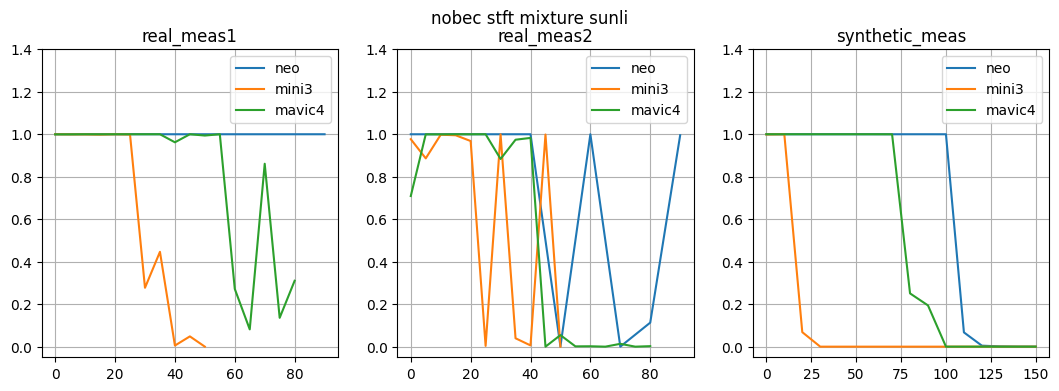

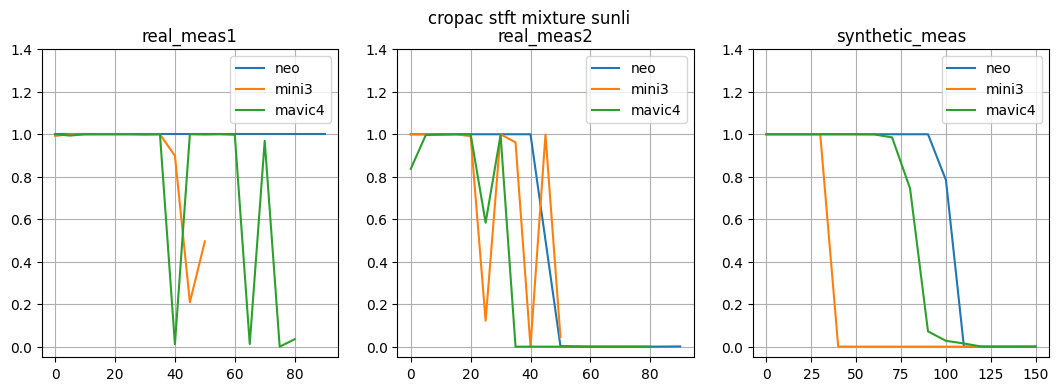

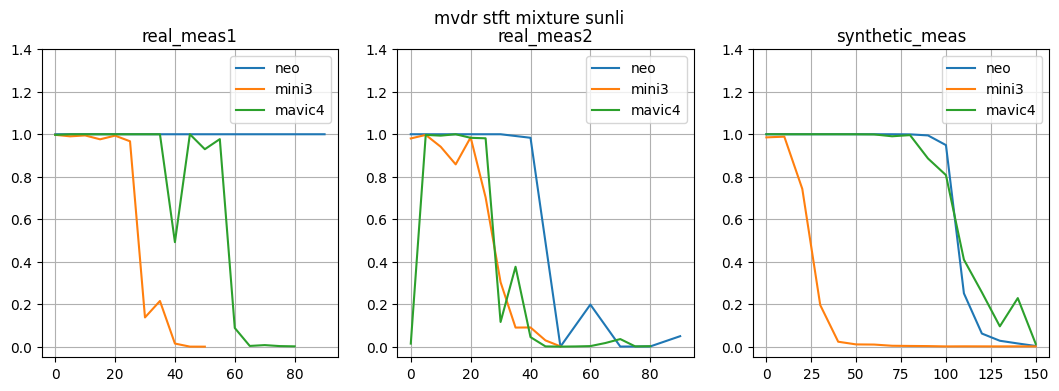

In [17]:
label_conversion = {
    "noise": 0,
    "neo": 1,
    "mini3": 2,
    "mavic4": 3
}

measurements = ["real_meas1", "real_meas2", "synthetic_meas"]

def prepare_features(images, height, width):
    images = np.asarray(images, dtype=np.float32)

    # Reshape flattened images to PyTorch's NCHW format.
    images = images.reshape(-1, channels, height, width)

    return torch.from_numpy(images)

def prepare_labels(labels, num_classes):
    labels = np.asarray(labels)

    # Convert one-hot labels (N, Q) to class indices if needed.
    if labels.ndim == 2:
        labels = labels.argmax(axis=1)

    return torch.as_tensor(labels, dtype=torch.long)

def process_measurement(path, algorithm, feature):
    data = {}
    inputs = {}
    distances = {}

    for k in label_conversion.keys():
        data[k] = []
        inputs[k] = []
        distances[k] = []

    path_files = [p.relative_to(".") for p in pathlib.Path(path).rglob("*.npy")]
    for pf in path_files:
        label, distance, algo, feat = str(pf.with_suffix("").name).split("_")
        if algo == algorithm and feat == feature:
            with open(str(pf), "rb") as fil:
                d = np.load(fil)
                data[label].append((d, int(distance)))

    for label, raw_data in data.items():
        for (d, dist) in raw_data:
            if feature == "mfcc":
                inputs[label].append(normalize_raw_mfcc(d[-FEATURE_LENGTH:]))
            else:
                inputs[label].append(normalize_raw_stft(d[-FEATURE_LENGTH:]))
            distances[label].append(dist)

    for k in label_conversion.keys():
            inputs[k] = np.array(inputs[k])
            distances[k] = np.array(distances[k])
            order = [i for i in range(len(distances[k]))]
            order = sorted(order, key=lambda idx: distances[k][idx])
            distances[k] = distances[k][order]
            inputs[k] = inputs[k][order]
    
    return inputs, distances

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL = "sunli"
for ALGO in ["nobec", "cropac", "mvdr"]:
    for FEAT in ["stft"]:
        for TRAINING_DATA in ["mixture"]:

            checkpoint = torch.load(f"../weights/{ALGO}_{FEAT}_{TRAINING_DATA}_{MODEL}.pth", map_location=device)

            height = checkpoint["height"]
            width = checkpoint["width"]
            channels = checkpoint["channels"]
            num_classes = checkpoint["num_classes"]

            model = SunLiCNN(width, height, num_classes).to(device)
            model.load_state_dict(checkpoint["model_state_dict"])
            model.eval()

            fig = plt.figure(figsize=(13, 4))
            for idx in range(len(measurements)):
                MEAS = measurements[idx]
                inputs, distances = process_measurement(f"../dataset/{MEAS}", ALGO, FEAT)

                ax = fig.add_subplot(131+idx)

                for label in inputs.keys():
                    if label == "noise":
                        continue
                    results = []
                    for i in range(len(inputs[label])):
                        x = prepare_features(inputs[label][i][None, ...], height, width).to(device)
                        with torch.no_grad():
                            output = nn.functional.softmax(model(x), dim=1)
                        output = output.squeeze(0).cpu().numpy()
                        results.append(output[label_conversion[label]])
                    ax.plot(distances[label], results, label=label)

                ax.set_ylim([-0.05, 1.4])
                ax.grid()
                ax.legend(loc="upper right")
                ax.set_title(MEAS)
            
            fig.suptitle(f"{ALGO} {FEAT} {TRAINING_DATA} {MODEL}")
            plt.show()
